# PondPredict — Foreign/Source Dataset Preparation

This notebook handles **only the foreign/source dataset**.

Project folders assumed:

## Important
Run the notebook **from top to bottom**.

A **DataFrame is not a separate file**. It is a table stored in Python memory.

- `df` = raw foreign dataset loaded from CSV
- `df_minute` = new DataFrame created after combining duplicate timestamps
- `df_hourly` = new DataFrame created later by converting minute-level data to hourly data

You create these simply by running the code cells below.



## 1. Import the libraries


In [2]:
import os

os.environ["KERAS_BACKEND"] = "torch"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score

import keras
from keras.models import Sequential
from keras.layers import LSTM, Dense, Dropout

## 2. Load the CSV into a DataFrame named `df`

This code reads the file inside the `data` folder and creates the Python DataFrame `df`.


In [3]:
df = pd.read_csv("../data/pond_iot_2023.csv")

print(type(df))
df.head()


<class 'pandas.DataFrame'>


,id,created_date,water_pH,TDS,water_temp
0,181775,1/26/2023 11:24,7.60,250,24.00
1,181777,1/26/2023 11:33,7.60,247,24.06
2,181778,1/26/2023 12:02,7.60,249,24.19
3,181780,1/26/2023 12:05,6.92,247,24.19
4,181782,1/26/2023 12:10,7.30,245,24.25


## 3. Inspect the raw dataset


In [4]:
print("Columns:", df.columns.tolist())
print("Rows:", df.shape[0])
print("Columns count:", df.shape[1])


Columns: ['id', 'created_date', 'water_pH', 'TDS', 'water_temp']
Rows: 118286
Columns count: 5


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 118286 entries, 0 to 118285
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            118286 non-null  int64  
 1   created_date  118286 non-null  str    
 2   water_pH      118286 non-null  float64
 3   TDS           118286 non-null  int64  
 4   water_temp    118286 non-null  float64
dtypes: float64(2), int64(2), str(1)
memory usage: 4.5 MB


In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate whole rows:", df.duplicated().sum())


Missing values:
id              0
created_date    0
water_pH        0
TDS             0
water_temp      0
dtype: int64

Duplicate whole rows: 0


In [7]:
df.describe()


,id,water_pH,TDS,water_temp
count,118286.000000,118286.000000,118286.000000,118286.000000
mean,392328.655716,7.508481,335.416491,24.656045
std,167174.066093,0.555780,43.738700,0.452398
min,181775.000000,6.500000,241.000000,24.000000
25%,256064.500000,7.050000,305.000000,24.310000
50%,355952.500000,7.490000,325.000000,24.560000
75%,537769.500000,7.980000,353.000000,24.940000
max,818730.000000,8.500000,498.000000,26.190000


## 4. Convert `created_date` from text to an actual datetime

The source dates use the format `1/26/2023 11:24`, which is month/day/year hour:minute.


In [8]:
df["created_date"] = pd.to_datetime(
    df["created_date"],
    format="%m/%d/%Y %H:%M"
)

print(df["created_date"].head(10))
print("\nData type:", df["created_date"].dtype)


0   2023-01-26 11:24:00
1   2023-01-26 11:33:00
2   2023-01-26 12:02:00
3   2023-01-26 12:05:00
4   2023-01-26 12:10:00
5   2023-01-26 12:11:00
6   2023-01-26 12:11:00
7   2023-01-26 12:12:00
8   2023-01-26 12:17:00
9   2023-01-26 12:18:00
Name: created_date, dtype: datetime64[us]

Data type: datetime64[us]


## 5. Sort the dataset chronologically


In [9]:
df = df.sort_values("created_date").reset_index(drop=True)

print("First date:", df["created_date"].min())
print("Last date:", df["created_date"].max())

df[["id", "created_date", "water_pH", "water_temp", "TDS"]].head(10)


First date: 2023-01-26 11:24:00
Last date: 2023-03-22 17:53:00


,id,created_date,water_pH,water_temp,TDS
0,181775,2023-01-26 11:24:00,7.60,24.00,250
1,181777,2023-01-26 11:33:00,7.60,24.06,247
2,181778,2023-01-26 12:02:00,7.60,24.19,249
3,181780,2023-01-26 12:05:00,6.92,24.19,247
4,181782,2023-01-26 12:10:00,7.30,24.25,245
5,181783,2023-01-26 12:11:00,6.96,24.25,247
6,181784,2023-01-26 12:11:00,7.60,24.25,247
7,181788,2023-01-26 12:12:00,6.88,24.25,247
8,181792,2023-01-26 12:17:00,7.60,24.25,247
9,181793,2023-01-26 12:18:00,7.19,24.25,247


## 6. Inspect raw pH and temperature over time


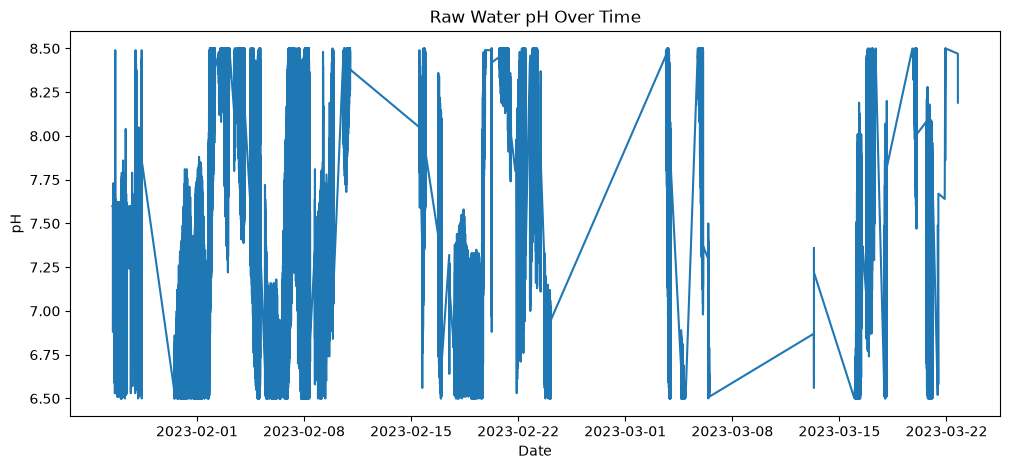

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df["created_date"], df["water_pH"])
plt.xlabel("Date")
plt.ylabel("pH")
plt.title("Raw Water pH Over Time")
plt.show()


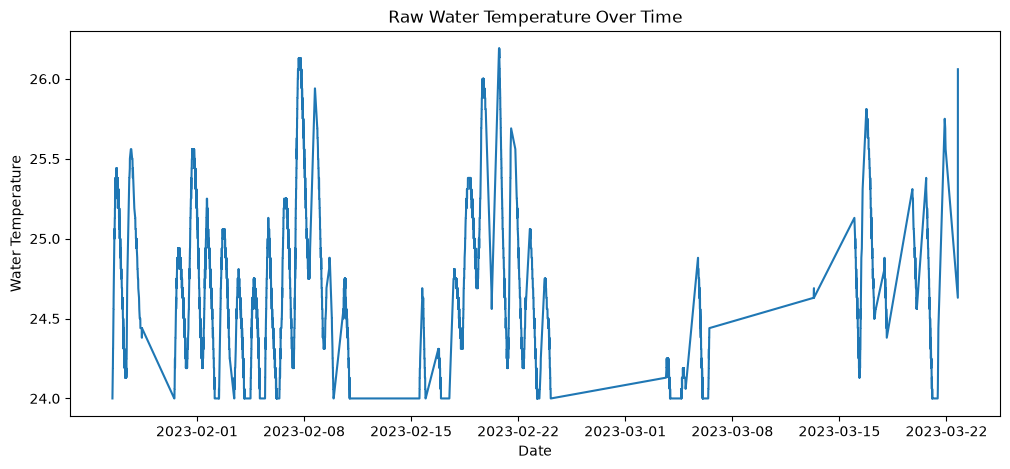

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(df["created_date"], df["water_temp"])
plt.xlabel("Date")
plt.ylabel("Water Temperature")
plt.title("Raw Water Temperature Over Time")
plt.show()


## 7. Check duplicate timestamps

The raw dataset contains many readings recorded during the same minute.  
This is different from duplicate whole rows.


In [12]:
print("Total rows:", len(df))
print("Unique timestamps:", df["created_date"].nunique())
print("Duplicate timestamp rows:", df["created_date"].duplicated().sum())

df["created_date"].value_counts().head(20)


Total rows: 118286
Unique timestamps: 19509
Duplicate timestamp rows: 98777


created_date
2023-02-04 22:37:00    24
2023-02-04 22:50:00    24
2023-02-05 00:16:00    24
2023-02-05 00:34:00    24
2023-02-05 01:46:00    24
2023-02-05 01:47:00    24
2023-03-03 19:55:00    24
2023-03-03 19:58:00    24
2023-03-03 20:24:00    24
2023-03-03 20:57:00    24
2023-02-04 21:01:00    23
2023-02-04 22:17:00    23
2023-02-04 22:46:00    23
2023-02-04 22:47:00    23
2023-02-04 22:51:00    23
2023-02-04 22:59:00    23
2023-02-04 23:03:00    23
2023-02-04 23:06:00    23
2023-02-04 23:16:00    23
2023-02-04 23:29:00    23
Name: count, dtype: int64

## 8. Inspect one repeated timestamp

This cell creates `duplicate_counts` and **also defines `sample_time`** before using it.  
The old notebook used `sample_time` without clearly creating it first.


In [13]:
duplicate_counts = df["created_date"].value_counts()
duplicate_counts = duplicate_counts[duplicate_counts > 1]

sample_time = duplicate_counts.index[0]

print("Sample repeated timestamp:", sample_time)
print("Number of readings at that timestamp:", duplicate_counts.iloc[0])

df[df["created_date"] == sample_time][
    ["id", "created_date", "water_pH", "water_temp", "TDS"]
].head(30)


Sample repeated timestamp: 2023-02-04 22:37:00
Number of readings at that timestamp: 24


,id,created_date,water_pH,water_temp,TDS
45925,315227,2023-02-04 22:37:00,7.20,24.5,313
45926,315226,2023-02-04 22:37:00,6.83,24.5,317
45927,315216,2023-02-04 22:37:00,8.35,24.5,319
45928,315224,2023-02-04 22:37:00,8.31,24.5,313
45929,315223,2023-02-04 22:37:00,8.15,24.5,317
45930,315222,2023-02-04 22:37:00,8.28,24.5,319
45931,315221,2023-02-04 22:37:00,6.72,24.5,319
45932,315220,2023-02-04 22:37:00,8.34,24.5,321
45933,315219,2023-02-04 22:37:00,7.36,24.5,317
45934,315218,2023-02-04 22:37:00,8.21,24.5,317


## 9. Check the time gaps between UNIQUE timestamps

We first remove repeated timestamps **only for this gap analysis**.


In [14]:
unique_times = (
    df[["created_date"]]
    .drop_duplicates()
    .sort_values("created_date")
    .reset_index(drop=True)
)

unique_times["time_difference"] = unique_times["created_date"].diff()

unique_times.head(10)


,created_date,time_difference
0,2023-01-26 11:24:00,NaT
1,2023-01-26 11:33:00,0 days 00:09:00
2,2023-01-26 12:02:00,0 days 00:29:00
3,2023-01-26 12:05:00,0 days 00:03:00
4,2023-01-26 12:10:00,0 days 00:05:00
5,2023-01-26 12:11:00,0 days 00:01:00
6,2023-01-26 12:12:00,0 days 00:01:00
7,2023-01-26 12:17:00,0 days 00:05:00
8,2023-01-26 12:18:00,0 days 00:01:00
9,2023-01-26 12:21:00,0 days 00:03:00


In [15]:
unique_times["time_difference"].value_counts().head(20)


time_difference
0 days 00:01:00    17317
0 days 00:02:00     1210
0 days 00:03:00      339
0 days 00:04:00      165
0 days 00:05:00      105
0 days 00:06:00       64
0 days 00:07:00       43
0 days 00:08:00       27
0 days 00:09:00       18
0 days 00:10:00       18
0 days 00:12:00       15
0 days 00:11:00       14
0 days 00:16:00       13
0 days 00:14:00       11
0 days 00:13:00       11
0 days 00:17:00       11
0 days 00:19:00        8
0 days 00:21:00        6
0 days 00:23:00        6
0 days 00:15:00        6
Name: count, dtype: int64

In [16]:
print("Median gap:", unique_times["time_difference"].median())
print("Most common gap:", unique_times["time_difference"].mode()[0])


Median gap: 0 days 00:01:00
Most common gap: 0 days 00:01:00


### Largest gaps


In [17]:
unique_times.sort_values(
    "time_difference",
    ascending=False
).head(20)


,created_date,time_difference
16542,2023-03-03 15:47:00,7 days 12:18:00
17656,2023-03-13 07:48:00,6 days 19:53:00
11882,2023-02-15 12:55:00,4 days 12:40:00
17658,2023-03-15 23:30:00,2 days 15:27:00
1370,2023-01-30 12:13:00,2 days 02:28:00
18798,2023-03-19 18:31:00,1 days 16:13:00
12183,2023-02-16 18:35:00,0 days 19:47:00
17170,2023-03-05 17:56:00,0 days 19:14:00
19506,2023-03-22 17:47:00,0 days 19:09:00
16909,2023-03-04 15:32:00,0 days 16:30:00


In [18]:
gaps = unique_times["time_difference"]

print("Gaps > 5 minutes:", (gaps > pd.Timedelta(minutes=5)).sum())
print("Gaps > 15 minutes:", (gaps > pd.Timedelta(minutes=15)).sum())
print("Gaps > 1 hour:", (gaps > pd.Timedelta(hours=1)).sum())
print("Gaps > 6 hours:", (gaps > pd.Timedelta(hours=6)).sum())
print("Gaps > 1 day:", (gaps > pd.Timedelta(days=1)).sum())


Gaps > 5 minutes: 372
Gaps > 15 minutes: 145
Gaps > 1 hour: 48
Gaps > 6 hours: 25
Gaps > 1 day: 6


## 10. Create `df_minute`

This creates a **new DataFrame in Python memory**.

It does **not** create a new Excel/CSV file and it does **not** overwrite `df`.

`df_minute` combines all readings that share the same recorded minute and uses the mean for `water_pH`, `water_temp`, and `TDS`.


In [19]:
df_minute = (
    df.groupby("created_date", as_index=False)[
        ["water_pH", "water_temp", "TDS"]
    ]
    .mean()
)

print(type(df_minute))
print("Original raw rows:", len(df))
print("Rows in df_minute:", len(df_minute))
print("Duplicate timestamps in df_minute:",
      df_minute["created_date"].duplicated().sum())

df_minute.head(10)


<class 'pandas.DataFrame'>
Original raw rows: 118286
Rows in df_minute: 19509
Duplicate timestamps in df_minute: 0


,created_date,water_pH,water_temp,TDS
0,2023-01-26 11:24:00,7.60,24.00,250.0
1,2023-01-26 11:33:00,7.60,24.06,247.0
2,2023-01-26 12:02:00,7.60,24.19,249.0
3,2023-01-26 12:05:00,6.92,24.19,247.0
4,2023-01-26 12:10:00,7.30,24.25,245.0
5,2023-01-26 12:11:00,7.28,24.25,247.0
6,2023-01-26 12:12:00,6.88,24.25,247.0
7,2023-01-26 12:17:00,7.60,24.25,247.0
8,2023-01-26 12:18:00,7.19,24.25,247.0
9,2023-01-26 12:21:00,7.54,24.31,247.0


### Check the minute-aggregated statistics


In [20]:
df_minute[["water_pH", "water_temp", "TDS"]].describe()


,water_pH,water_temp,TDS
count,19509.000000,19509.000000,19509.000000
mean,7.492675,24.712274,338.768993
std,0.506003,0.478321,43.568879
min,6.500000,24.000000,244.333333
25%,7.088000,24.310000,304.900000
50%,7.442353,24.644118,331.333333
75%,7.885000,25.000000,369.000000
max,8.500000,26.190000,498.000000


### Plot the minute-aggregated data


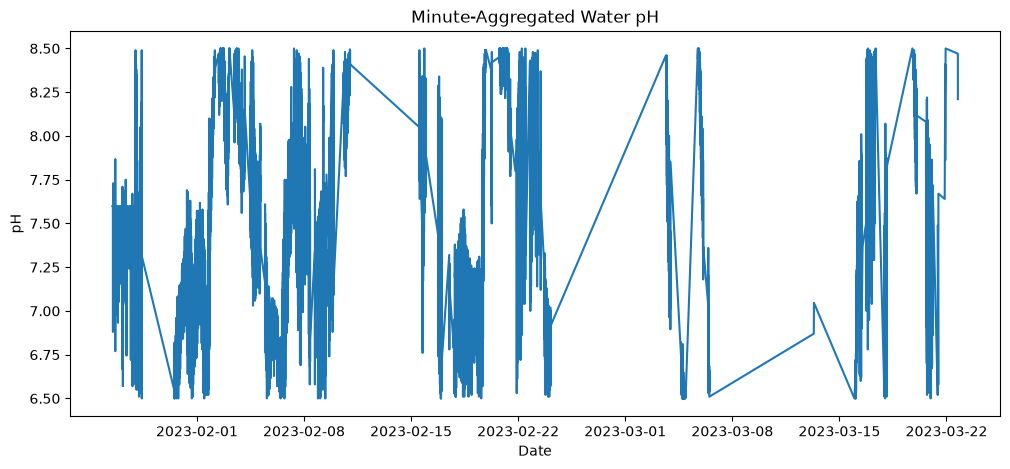

In [21]:
plt.figure(figsize=(12, 5))
plt.plot(df_minute["created_date"], df_minute["water_pH"])
plt.xlabel("Date")
plt.ylabel("pH")
plt.title("Minute-Aggregated Water pH")
plt.show()


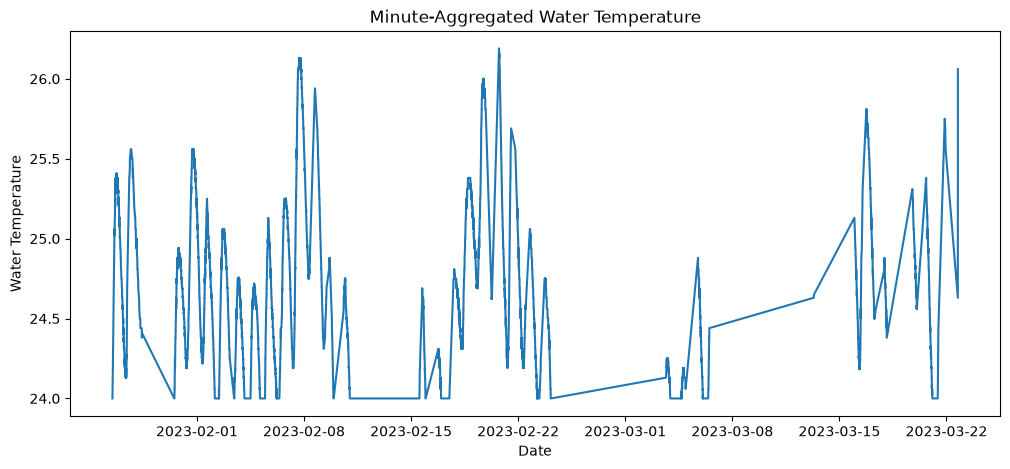

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(df_minute["created_date"], df_minute["water_temp"])
plt.xlabel("Date")
plt.ylabel("Water Temperature")
plt.title("Minute-Aggregated Water Temperature")
plt.show()


# NEXT STAGE — Hourly Source Data

The Philippine target dataset is planned to be hourly, so the next source-data version will also be examined at hourly resolution.

**Do not interpolate long missing gaps yet.**

The cells below only create and inspect an hourly DataFrame.


## 11. Create `df_hourly`

This creates another **new DataFrame in Python memory** named `df_hourly`.

It uses `df_minute` as the source. Hours with no observations will contain `NaN`.


In [23]:
df_hourly = (
    df_minute
    .set_index("created_date")
    .resample("1h")[["water_pH", "water_temp", "TDS"]]
    .mean()
)

print(type(df_hourly))
df_hourly.head(20)


<class 'pandas.DataFrame'>


,water_pH,water_temp,TDS
created_date,,,
2023-01-26 11:00:00,7.600000,24.030000,248.500000
2023-01-26 12:00:00,7.390000,24.329333,248.133333
2023-01-26 13:00:00,7.442857,24.598571,250.857143
2023-01-26 14:00:00,7.447223,25.060671,248.002378
2023-01-26 15:00:00,7.408006,25.202873,250.122906
2023-01-26 16:00:00,7.405294,25.342974,255.777381
2023-01-26 17:00:00,7.394258,25.383110,260.299680
2023-01-26 18:00:00,7.400591,25.380953,264.936636
2023-01-26 19:00:00,7.387571,25.359538,266.781115


## 12. Inspect missing hourly observations


In [24]:
print("Total hourly rows:", len(df_hourly))
print("Hours missing pH:", df_hourly["water_pH"].isna().sum())
print("Hours missing temperature:", df_hourly["water_temp"].isna().sum())

missing_hourly_percent = (
    df_hourly["water_pH"].isna().sum()
    / len(df_hourly)
    * 100
)

print("Missing hourly data:", round(missing_hourly_percent, 2), "%")


Total hourly rows: 1327
Hours missing pH: 837
Hours missing temperature: 837
Missing hourly data: 63.07 %


## 13. Count how many minute observations contribute to each hour


In [25]:
hourly_counts = (
    df_minute
    .set_index("created_date")
    .resample("1h")["water_pH"]
    .count()
)

hourly_counts.describe()


count    1327.000000
mean       14.701583
std        23.334052
min         0.000000
25%         0.000000
50%         0.000000
75%        26.500000
max        60.000000
Name: water_pH, dtype: float64

In [26]:
print("Hours with exactly 1 observation:", (hourly_counts == 1).sum())
print(
    "Hours with 1-9 observations:",
    ((hourly_counts > 0) & (hourly_counts < 10)).sum()
)


Hours with exactly 1 observation: 15
Hours with 1-9 observations: 79


## 14. Optional: put `created_date` back as a normal column

Run this only after the hourly inspection above.


In [27]:
df_hourly = df_hourly.reset_index()

df_hourly.head()


,created_date,water_pH,water_temp,TDS
0,2023-01-26 11:00:00,7.600000,24.030000,248.500000
1,2023-01-26 12:00:00,7.390000,24.329333,248.133333
2,2023-01-26 13:00:00,7.442857,24.598571,250.857143
3,2023-01-26 14:00:00,7.447223,25.060671,248.002378
4,2023-01-26 15:00:00,7.408006,25.202873,250.122906


# STOP HERE

At this point, do **not** yet:

- interpolate missing values
- remove outliers
- scale the data
- choose sequence length
- choose forecasting horizon
- split train/validation/test
- build the LSTM

Those decisions come after we inspect the hourly missing-data results.


## 15. Check hourly missing data

This section checks how many hourly rows contain actual pH and temperature observations and how many hourly rows are missing.

In [28]:
print("Total hourly rows:", len(df_hourly))

print(
    "Hours with pH data:",
    df_hourly["water_pH"].notna().sum()
)

print(
    "Hours missing pH:",
    df_hourly["water_pH"].isna().sum()
)

print(
    "Hours with temperature data:",
    df_hourly["water_temp"].notna().sum()
)

print(
    "Hours missing temperature:",
    df_hourly["water_temp"].isna().sum()
)

Total hourly rows: 1327
Hours with pH data: 490
Hours missing pH: 837
Hours with temperature data: 490
Hours missing temperature: 837


In [29]:
missing_percent = (
    df_hourly["water_pH"].isna().sum()
    / len(df_hourly)
    * 100
)

print(
    "Percentage of hourly rows missing:",
    round(missing_percent, 2),
    "%"
)

Percentage of hourly rows missing: 63.07 %


## 16. Identify continuous hourly segments

This section identifies continuous blocks of hourly observations. Long missing periods should not be treated as if the readings were consecutive.

In [30]:
df_hourly["has_data"] = df_hourly["water_pH"].notna()

In [31]:
df_hourly["segment_id"] = (
    df_hourly["has_data"]
    != df_hourly["has_data"].shift()
).cumsum()

In [32]:
segments = (
    df_hourly[df_hourly["has_data"]]
    .groupby("segment_id")
    .agg(
        start=("created_date", "min"),
        end=("created_date", "max"),
        hours=("created_date", "count")
    )
    .sort_values("hours", ascending=False)
)

segments.head(20)

,start,end,hours
segment_id,,,
11,2023-01-30 12:00:00,2023-02-02 04:00:00,65
43,2023-02-17 18:00:00,2023-02-19 21:00:00,52
21,2023-02-06 09:00:00,2023-02-08 09:00:00,49
1,2023-01-26 11:00:00,2023-01-27 11:00:00,25
19,2023-02-05 10:00:00,2023-02-06 05:00:00,20
47,2023-02-20 17:00:00,2023-02-21 12:00:00,20
15,2023-02-03 10:00:00,2023-02-04 03:00:00,18
13,2023-02-02 10:00:00,2023-02-03 03:00:00,18
17,2023-02-04 11:00:00,2023-02-05 03:00:00,17


## 17. Decision on Missing Hourly Data

After hourly resampling, the source dataset contained 1,327 hourly time slots. Of these, 490 hours contained observed pH and water-temperature data, while 837 hours were missing, corresponding to 63.07% missing hourly observations.

Because the dataset contains substantial missing periods, including multi-hour and multi-day gaps, the missing portions will not be globally interpolated. Instead, the observed data will be divided into continuous hourly segments. LSTM sequences will later be generated only within valid continuous segments so that no sequence crosses a missing-data gap.

In [33]:
print("Number of continuous observed segments:", len(segments))

print(
    "Longest continuous segment:",
    segments["hours"].max(),
    "hours"
)

print(
    "Shortest continuous segment:",
    segments["hours"].min(),
    "hours"
)

Number of continuous observed segments: 42
Longest continuous segment: 65 hours
Shortest continuous segment: 1 hours


In [34]:
segments["hours"].describe()

count    42.000000
mean     11.666667
std      14.035958
min       1.000000
25%       2.000000
50%       8.000000
75%      15.750000
max      65.000000
Name: hours, dtype: float64

## 18. Preliminary Sequence-Length Feasibility

Before selecting the final LSTM sequence length, candidate historical windows are checked against the lengths of the continuous hourly segments.

For a one-step-ahead forecast, a segment must contain more observations than the selected sequence length.

In [35]:
candidate_windows = [6, 12, 18, 24, 36, 48]

for window in candidate_windows:
    usable_segments = (segments["hours"] > window).sum()

    print(
        f"{window}-hour window:",
        usable_segments,
        "usable segments"
    )

6-hour window: 22 usable segments
12-hour window: 14 usable segments
18-hour window: 6 usable segments
24-hour window: 4 usable segments
36-hour window: 3 usable segments
48-hour window: 3 usable segments


In [36]:
for window in candidate_windows:

    sequence_counts = (
        segments["hours"] - window
    ).clip(lower=0)

    total_sequences = sequence_counts.sum()

    print(
        f"{window}-hour window:",
        int(total_sequences),
        "possible sequences"
    )

6-hour window: 306 possible sequences
12-hour window: 190 possible sequences
18-hour window: 123 possible sequences
24-hour window: 95 possible sequences
36-hour window: 58 possible sequences
48-hour window: 22 possible sequences


## 19. Outlier Assessment

Outlier assessment is performed on the hourly aggregated source data. Missing hourly rows are excluded from this assessment because they do not represent observed measurements.

In [37]:
df_hourly_observed = df_hourly.dropna(
    subset=["water_pH", "water_temp"]
).copy()

print("Observed hourly rows:", len(df_hourly_observed))

df_hourly_observed[
    ["water_pH", "water_temp", "TDS"]
].describe()

Observed hourly rows: 490


,water_pH,water_temp,TDS
count,490.000000,490.000000,490.000000
mean,7.496987,24.737425,343.535757
std,0.498156,0.504990,46.727401
min,6.500000,24.000000,248.002378
25%,7.111495,24.338214,304.806949
50%,7.434118,24.666652,340.951219
75%,7.850097,25.038884,374.416667
max,8.475000,26.190000,484.037037


C:\Users\Admin\AppData\Local\Temp\ipykernel_30900\1505870654.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


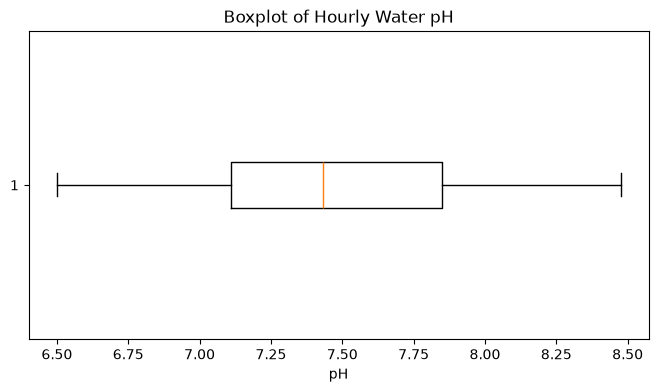

In [38]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    df_hourly_observed["water_pH"].dropna(),
    vert=False
)

plt.xlabel("pH")
plt.title("Boxplot of Hourly Water pH")

plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_30900\1128296525.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


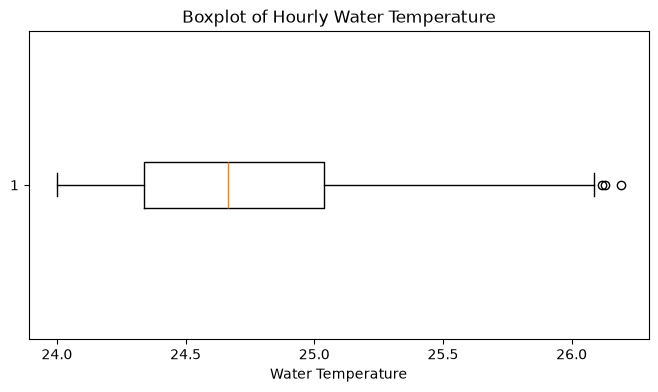

In [39]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    df_hourly_observed["water_temp"].dropna(),
    vert=False
)

plt.xlabel("Water Temperature")
plt.title("Boxplot of Hourly Water Temperature")

plt.show()

### IQR-Based Outlier Detection

The interquartile range (IQR) method is used to identify observations lying below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Identified observations will first be examined rather than automatically removed.

In [40]:
def check_iqr_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print("Variable:", column)
    print("Q1:", q1)
    print("Q3:", q3)
    print("IQR:", iqr)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))
    print()

    return outliers

In [41]:
ph_outliers = check_iqr_outliers(
    df_hourly_observed,
    "water_pH"
)

temp_outliers = check_iqr_outliers(
    df_hourly_observed,
    "water_temp"
)

Variable: water_pH
Q1: 7.111495287698412
Q3: 7.8500965707903205
IQR: 0.7386012830919082
Lower bound: 6.00359336306055
Upper bound: 8.957998495428182
Number of potential outliers: 0

Variable: water_temp
Q1: 24.338214386602097
Q3: 25.038883578263842
IQR: 0.7006691916617456
Lower bound: 23.28721059910948
Upper bound: 26.08988736575646
Number of potential outliers: 3



## 20. Inspection of Potential Temperature Outliers

The IQR method identified three potential water-temperature outliers. These observations are inspected together with their timestamps before deciding whether they represent erroneous measurements or valid high-temperature observations.

In [42]:
temp_outliers[
    ["created_date", "water_pH", "water_temp", "TDS"]
]

,created_date,water_pH,water_temp,TDS
293,2023-02-07 16:00:00,7.713133,26.119021,337.478075
294,2023-02-07 17:00:00,7.670762,26.129000,339.738095
606,2023-02-20 17:00:00,8.450000,26.190000,373.000000


In [43]:
for index, row in temp_outliers.iterrows():

    outlier_time = row["created_date"]

    print("\nOutlier timestamp:", outlier_time)
    print("Temperature:", row["water_temp"])

    nearby = df_hourly_observed[
        (df_hourly_observed["created_date"] >= outlier_time - pd.Timedelta(hours=3))
        &
        (df_hourly_observed["created_date"] <= outlier_time + pd.Timedelta(hours=3))
    ]

    display(
        nearby[
            ["created_date", "water_pH", "water_temp"]
        ]
    )


Outlier timestamp: 2023-02-07 16:00:00
Temperature: 26.119020833333334


,created_date,water_pH,water_temp
290,2023-02-07 13:00:00,7.787289,25.827958
291,2023-02-07 14:00:00,7.648533,26.021560
292,2023-02-07 15:00:00,7.727767,26.060700
293,2023-02-07 16:00:00,7.713133,26.119021
294,2023-02-07 17:00:00,7.670762,26.129000
295,2023-02-07 18:00:00,7.523177,26.072578
296,2023-02-07 19:00:00,7.622331,26.041584



Outlier timestamp: 2023-02-07 17:00:00
Temperature: 26.129


,created_date,water_pH,water_temp
291,2023-02-07 14:00:00,7.648533,26.021560
292,2023-02-07 15:00:00,7.727767,26.060700
293,2023-02-07 16:00:00,7.713133,26.119021
294,2023-02-07 17:00:00,7.670762,26.129000
295,2023-02-07 18:00:00,7.523177,26.072578
296,2023-02-07 19:00:00,7.622331,26.041584
297,2023-02-07 20:00:00,7.617684,25.952248



Outlier timestamp: 2023-02-20 17:00:00
Temperature: 26.19


,created_date,water_pH,water_temp
606,2023-02-20 17:00:00,8.450000,26.190000
607,2023-02-20 18:00:00,8.465833,26.085833
608,2023-02-20 19:00:00,8.442339,25.931452
609,2023-02-20 20:00:00,8.406509,25.706577


## 21. Outlier Assessment Decision

The IQR assessment identified no potential outliers for hourly water pH. Three hourly water-temperature observations exceeded the upper IQR threshold. However, the identified values were only slightly above the statistical boundary and remained within the observed temperature range of the source dataset.

Because the observations were not automatically assumed to be erroneous sensor measurements, they were retained unless contextual inspection of neighboring observations indicated measurement anomalies. Thus, no pH observations were removed, and the identified temperature observations were retained for subsequent preprocessing.

## 22. Final Modeling Variables

The LSTM forecasting model will use only two water-quality variables:

- `water_pH`
- `water_temp`

These two variables will serve as both the model inputs and the forecast targets.

The `TDS` variable is excluded from the modeling pipeline because the study is focused specifically on forecasting pH and water temperature. The original TDS values remain preserved in the raw source dataset but will not be used for model training, scaling, sequence generation, or prediction.

## 23. Create the Source Modeling DataFrame

A separate modeling DataFrame is created from the observed hourly source data. Only the timestamp, water pH, water temperature, and segment identifier are retained.

The original DataFrames remain unchanged.


In [44]:
df_model = df_hourly_observed[
    [
        "created_date",
        "water_pH",
        "water_temp",
        "segment_id"
    ]
].copy()

df_model.head()

,created_date,water_pH,water_temp,segment_id
0,2023-01-26 11:00:00,7.600000,24.030000,1
1,2023-01-26 12:00:00,7.390000,24.329333,1
2,2023-01-26 13:00:00,7.442857,24.598571,1
3,2023-01-26 14:00:00,7.447223,25.060671,1
4,2023-01-26 15:00:00,7.408006,25.202873,1


## 24. Check the Modeling DataFrame

The source modeling DataFrame is checked to confirm the number of rows, selected columns, and presence of missing values before further preprocessing.

In [45]:
print("Modeling rows:", len(df_model))

print("\nColumns:")
print(df_model.columns.tolist())

print("\nMissing values:")
print(df_model.isnull().sum())

df_model.head(10)

Modeling rows: 490

Columns:
['created_date', 'water_pH', 'water_temp', 'segment_id']

Missing values:
created_date    0
water_pH        0
water_temp      0
segment_id      0
dtype: int64


,created_date,water_pH,water_temp,segment_id
0,2023-01-26 11:00:00,7.600000,24.030000,1
1,2023-01-26 12:00:00,7.390000,24.329333,1
2,2023-01-26 13:00:00,7.442857,24.598571,1
3,2023-01-26 14:00:00,7.447223,25.060671,1
4,2023-01-26 15:00:00,7.408006,25.202873,1
5,2023-01-26 16:00:00,7.405294,25.342974,1
6,2023-01-26 17:00:00,7.394258,25.383110,1
7,2023-01-26 18:00:00,7.400591,25.380953,1
8,2023-01-26 19:00:00,7.387571,25.359538,1
9,2023-01-26 20:00:00,7.368318,25.285136,1


## 25. Scaling Method

Min-max normalization will be used to scale `water_pH` and `water_temp` before LSTM training.

To prevent data leakage, the scaler will be fitted using only the training portion of the source dataset. The same fitted scaler will then be applied to the validation and test datasets.

Scaling will therefore be performed only after the chronological train-validation-test split has been established.

## 26. Forecasting Horizon

The forecasting horizon is set to one hour ahead.

The LSTM model will use a sequence of previous hourly pH and water-temperature observations to predict the next hourly values of both variables.

## 27. Initial Sequence Length

A six-hour historical window is selected as the initial sequence length.

This provides the LSTM with short-term temporal context while retaining more usable sequences from the fragmented hourly source dataset.

Longer sequence lengths substantially reduce the number of available training sequences because many continuous observation segments are relatively short.

A 12-hour sequence length may later be evaluated during model experimentation for comparison.

## 28. Chronological Data Split

The source modeling dataset will be divided chronologically into:

- 70% training data
- 15% validation data
- 15% test data

The observations will not be randomly shuffled because the temporal order of the time series must be preserved.

Earlier observations will be used for training, followed by later observations for validation and testing.


## 29.

In [46]:
total_rows = len(df_model)

train_end = int(total_rows * 0.70)
val_end = int(total_rows * 0.85)

print("Total rows:", total_rows)
print("Training rows:", train_end)
print("Validation rows:", val_end - train_end)
print("Test rows:", total_rows - val_end)

Total rows: 490
Training rows: 343
Validation rows: 73
Test rows: 74


## 30. Create the Split DataFrames

Separate DataFrames are created for the training, validation, and test portions of the source dataset using the chronological split boundaries.

In [47]:
train_df = df_model.iloc[:train_end].copy()

val_df = df_model.iloc[
    train_end:val_end
].copy()

test_df = df_model.iloc[
    val_end:
].copy()

In [48]:
print("Training:")
print(train_df["created_date"].min(), "to", train_df["created_date"].max())
print("Rows:", len(train_df))

print("\nValidation:")
print(val_df["created_date"].min(), "to", val_df["created_date"].max())
print("Rows:", len(val_df))

print("\nTest:")
print(test_df["created_date"].min(), "to", test_df["created_date"].max())
print("Rows:", len(test_df))

Training:
2023-01-26 11:00:00 to 2023-02-21 00:00:00
Rows: 343

Validation:
2023-02-21 01:00:00 to 2023-03-04 22:00:00
Rows: 73

Test:
2023-03-05 17:00:00 to 2023-03-22 17:00:00
Rows: 74


## 31. Fit the MinMax Scaler

The min-max scaler is fitted using only the training dataset to prevent information from the validation and test periods from influencing model training.

The same fitted scaler is then used to transform all three datasets.

In [49]:
scaler = MinMaxScaler()

scaler.fit(
    train_df[["water_pH", "water_temp"]]
)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](2,)","[ 8.47,26.19]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](2,)","[ 6.59,24. ]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](2,)","[1.88,2.19]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['water_pH','water_temp']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](2,)","[ -3.5 ,-10.96]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,343


In [50]:
train_scaled = scaler.transform(
    train_df[["water_pH", "water_temp"]]
)

val_scaled = scaler.transform(
    val_df[["water_pH", "water_temp"]]
)

test_scaled = scaler.transform(
    test_df[["water_pH", "water_temp"]]
)

print("Training scaled shape:", train_scaled.shape)
print("Validation scaled shape:", val_scaled.shape)
print("Test scaled shape:", test_scaled.shape)

Training scaled shape: (343, 2)
Validation scaled shape: (73, 2)
Test scaled shape: (74, 2)


## 32


In [51]:
print("First 5 scaled training rows:")
print(train_scaled[:5])

print("\nMinimum values in training:")
print(train_scaled.min(axis=0))

print("\nMaximum values in training:")
print(train_scaled.max(axis=0))

First 5 scaled training rows:
[[0.53777187 0.01369863]
 [0.42619957 0.15038052]
 [0.45428239 0.27332029]
 [0.45660171 0.48432471]
 [0.43576607 0.54925708]]

Minimum values in training:
[0. 0.]

Maximum values in training:
[1. 1.]


## 33. Segment-Safe Sequence Generation

LSTM sequences are generated only within continuous hourly segments.

A sequence is not allowed to cross a segment boundary because observations separated by missing hourly periods must not be treated as consecutive time steps.

The initial sequence length is six hours, and the forecast horizon is one hour ahead.

In [52]:
SEQUENCE_LENGTH = 6

def create_segment_sequences(dataframe, scaled_values, sequence_length):
    X = []
    y = []

    segment_ids = dataframe["segment_id"].to_numpy()

    for i in range(sequence_length, len(dataframe)):

        input_segment = segment_ids[
            i - sequence_length:i
        ]

        target_segment = segment_ids[i]

        if np.all(input_segment == target_segment):

            X.append(
                scaled_values[i - sequence_length:i]
            )

            y.append(
                scaled_values[i]
            )

    return np.array(X), np.array(y)

In [53]:
X_train, y_train = create_segment_sequences(
    train_df,
    train_scaled,
    SEQUENCE_LENGTH
)

X_val, y_val = create_segment_sequences(
    val_df,
    val_scaled,
    SEQUENCE_LENGTH
)

X_test, y_test = create_segment_sequences(
    test_df,
    test_scaled,
    SEQUENCE_LENGTH
)

## 34


In [54]:
print("Training sequences:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation sequences:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTest sequences:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training sequences:
X_train: (236, 6, 2)
y_train: (236, 2)

Validation sequences:
X_val: (35, 6, 2)
y_val: (35, 2)

Test sequences:
X_test: (29, 6, 2)
y_test: (29, 2)


## 35. Final Sequence Sanity Check

The generated training, validation, and test sequences are checked for missing or non-finite values before model development.

In [55]:
print("NaN values:")

print("X_train:", np.isnan(X_train).sum())
print("y_train:", np.isnan(y_train).sum())

print("X_val:", np.isnan(X_val).sum())
print("y_val:", np.isnan(y_val).sum())

print("X_test:", np.isnan(X_test).sum())
print("y_test:", np.isnan(y_test).sum())

NaN values:
X_train: 0
y_train: 0
X_val: 0
y_val: 0
X_test: 0
y_test: 0


In [56]:
print("Final shapes:")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Final shapes:
X_train: (236, 6, 2)
y_train: (236, 2)
X_val: (35, 6, 2)
y_val: (35, 2)
X_test: (29, 6, 2)
y_test: (29, 2)


## 38. Modeling Framework

The LSTM forecasting model is implemented using Keras 3 with the PyTorch backend.

Keras provides the high-level interface for constructing, training, and evaluating the LSTM model, while PyTorch serves as the computational backend.

TensorFlow is not used for the final model implementation.

## 39. Baseline Source LSTM

An initial LSTM model is created to establish baseline forecasting performance using the foreign source dataset.

The baseline model uses a simple architecture before hyperparameter tuning and additional regularization are performed.


In [57]:
baseline_model = Sequential([
    LSTM(
        32,
        input_shape=(6, 2)
    ),
    Dense(2)
])

c:\Users\Admin\Datas\PondPredict\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 40


In [58]:
baseline_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [59]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,546 (17.76 KB)

 Trainable params: 4,546 (17.76 KB)

 Non-trainable params: 0 (0.00 B)

## 41. Baseline Model Training

The baseline LSTM is initially trained using the Adam optimizer and mean squared error loss.

This first training run is used to establish reference performance before hyperparameter tuning and additional overfitting-control methods are introduced.

In [60]:
history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16,
    verbose=1
)

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2051 - mae: 0.3899 - val_loss: 0.0827 - val_mae: 0.2184
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0821 - mae: 0.2213 - val_loss: 0.0307 - val_mae: 0.1583
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0331 - mae: 0.1426 - val_loss: 0.0468 - val_mae: 0.1799
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0264 - mae: 0.1310 - val_loss: 0.0294 - val_mae: 0.1461
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0227 - mae: 0.1134 - val_loss: 0.0243 - val_mae: 0.1287
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0208 - mae: 0.1109 - val_loss: 0.0264 - val_mae: 0.1347
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0202 - mae: 0.1110 - val_loss: 0.0232 - val_mae: 0.1215
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0193 - mae: 0.1063 - val_loss: 0.0236 - val_mae: 0.1238
Epoch 9/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0189 - mae: 

## 42. Training and Validation Loss

The training and validation loss curves are plotted to inspect model convergence and identify possible overfitting behavior.

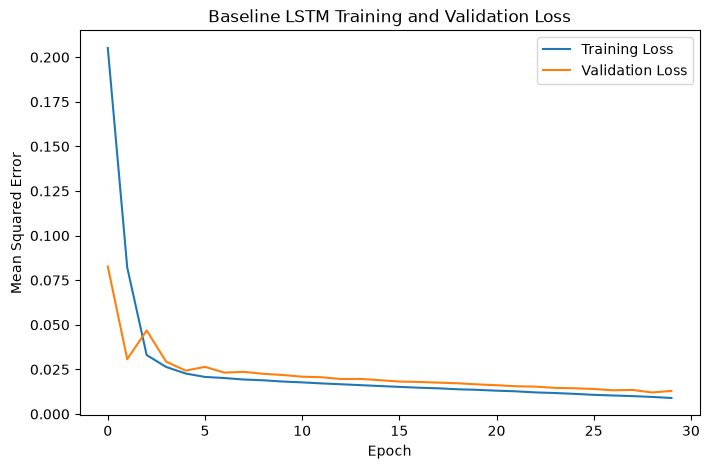

In [61]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Baseline LSTM Training and Validation Loss")

plt.legend()
plt.show()

## 43. Training and Validation MAE

The mean absolute error of the training and validation sets is plotted to further inspect the learning behavior of the baseline LSTM.


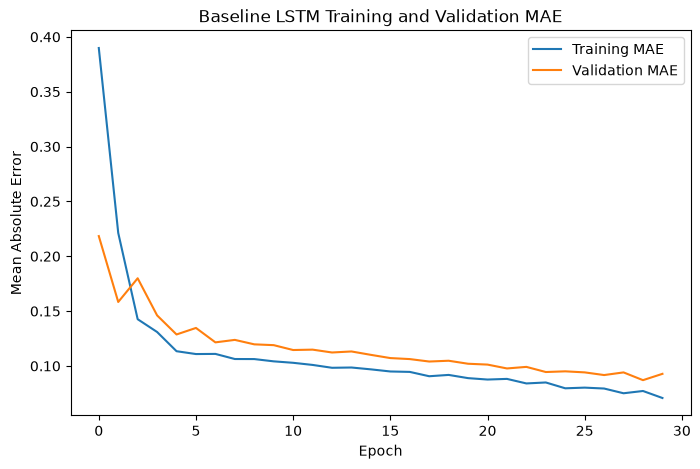

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["mae"],
    label="Training MAE"
)

plt.plot(
    history.history["val_mae"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.title("Baseline LSTM Training and Validation MAE")

plt.legend()
plt.show()

## 44. Baseline Test Predictions

The trained baseline source LSTM is applied to the test sequences to generate one-hour-ahead predictions for water pH and water temperature.

The predictions are initially produced in normalized form because the model was trained using min-max-scaled data.

In [63]:
y_pred_scaled = baseline_model.predict(
    X_test,
    verbose=0
)

print("Prediction shape:", y_pred_scaled.shape)
print("Actual target shape:", y_test.shape)

Prediction shape: (29, 2)
Actual target shape: (29, 2)


## 45. Inverse Transformation of Predictions

The predicted and actual test values are transformed back to their original measurement scales using the MinMaxScaler fitted on the source training data.

This allows forecasting errors to be interpreted using the original pH and water-temperature units.

In [64]:
y_pred_original = scaler.inverse_transform(
    y_pred_scaled
)

y_test_original = scaler.inverse_transform(
    y_test
)

print("First 5 actual values:")
print(y_test_original[:5])

print("\nFirst 5 predicted values:")
print(y_pred_original[:5])

First 5 actual values:
[[ 7.90060361 24.26929359]
 [ 7.77960071 24.15673956]
 [ 7.73834146 24.04203756]
 [ 7.56298144 24.        ]
 [ 7.33710122 24.37046373]]

First 5 predicted values:
[[ 8.346071  24.483746 ]
 [ 8.233954  24.407223 ]
 [ 8.109945  24.328718 ]
 [ 7.9993954 24.241634 ]
 [ 7.0969944 24.612429 ]]


## 46. Baseline Evaluation Metrics

The baseline source model is evaluated separately for water pH and water temperature using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination (R²)

The metrics are calculated after inverse transformation so that MAE and RMSE are expressed in the original measurement scales.

In [65]:
# Actual values
actual_ph = y_test_original[:, 0]
actual_temp = y_test_original[:, 1]

# Predicted values
pred_ph = y_pred_original[:, 0]
pred_temp = y_pred_original[:, 1]


# pH metrics
ph_mae = mean_absolute_error(
    actual_ph,
    pred_ph
)

ph_rmse = np.sqrt(
    mean_squared_error(
        actual_ph,
        pred_ph
    )
)

ph_r2 = r2_score(
    actual_ph,
    pred_ph
)


# Temperature metrics
temp_mae = mean_absolute_error(
    actual_temp,
    pred_temp
)

temp_rmse = np.sqrt(
    mean_squared_error(
        actual_temp,
        pred_temp
    )
)

temp_r2 = r2_score(
    actual_temp,
    pred_temp
)


print("WATER pH")
print("MAE :", ph_mae)
print("RMSE:", ph_rmse)
print("R²  :", ph_r2)

print("\nWATER TEMPERATURE")
print("MAE :", temp_mae)
print("RMSE:", temp_rmse)
print("R²  :", temp_r2)

WATER pH
MAE : 0.1963897357651319
RMSE: 0.23972796520607856
R²  : 0.5704207421501462

WATER TEMPERATURE
MAE : 0.19708729743755746
RMSE: 0.2342839976684332
R²  : 0.6156920499017806


## 47


In [66]:
baseline_metrics = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water Temperature"
    ],
    "MAE": [
        ph_mae,
        temp_mae
    ],
    "RMSE": [
        ph_rmse,
        temp_rmse
    ],
    "R2": [
        ph_r2,
        temp_r2
    ]
})

baseline_metrics

,Variable,MAE,RMSE,R2
0,Water pH,0.196390,0.239728,0.570421
1,Water Temperature,0.197087,0.234284,0.615692


## 48. Actual versus Predicted Water pH

The predicted one-hour-ahead water pH values are compared with the corresponding actual test values to visually assess forecasting behavior.

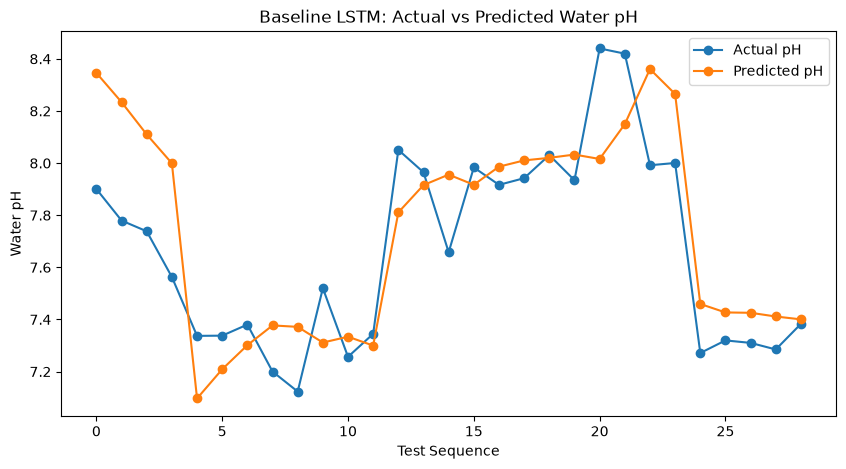

In [67]:
plt.figure(figsize=(10, 5))

plt.plot(
    actual_ph,
    label="Actual pH",
    marker="o"
)

plt.plot(
    pred_ph,
    label="Predicted pH",
    marker="o"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water pH")
plt.title("Baseline LSTM: Actual vs Predicted Water pH")

plt.legend()
plt.show()

## 49. Actual versus Predicted Water Temperature

The predicted one-hour-ahead water-temperature values are compared with the corresponding actual test values to visually assess forecasting behavior.

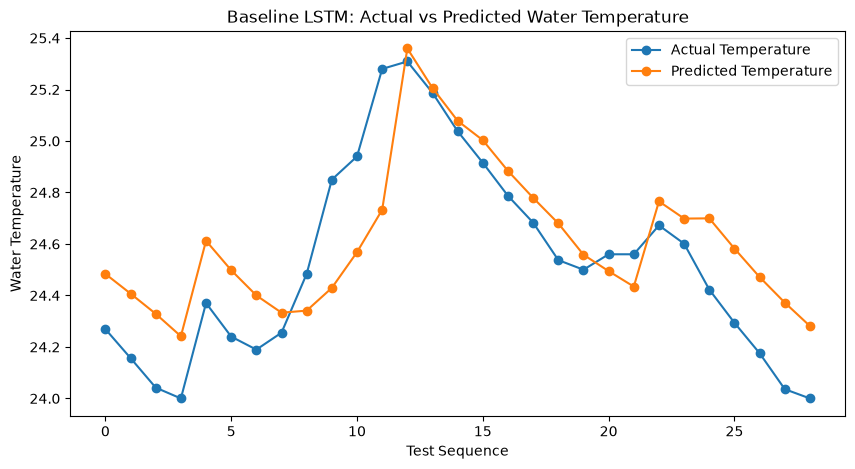

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    actual_temp,
    label="Actual Temperature",
    marker="o"
)

plt.plot(
    pred_temp,
    label="Predicted Temperature",
    marker="o"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water Temperature")
plt.title(
    "Baseline LSTM: Actual vs Predicted Water Temperature"
)

plt.legend()
plt.show()

## 50. Baseline Source Model Results

The initial source LSTM was evaluated on the held-out source test set using MAE, RMSE, and R² after inverse transformation to the original pH and temperature scales.

The baseline model produced the following results:

| Variable | MAE | RMSE | R² |
|---|---:|---:|---:|
| Water pH | 0.2085 | 0.2528 | 0.5224 |
| Water Temperature | 0.1729 | 0.2047 | 0.7067 |

The baseline generally followed the temporal behavior of both variables. Water-temperature predictions showed stronger agreement with the observed values than pH predictions. The pH predictions followed the overall pattern but showed larger errors during abrupt changes.

These results serve as the reference performance before hyperparameter tuning and overfitting-control methods are evaluated.

In [69]:
baseline_metrics.to_csv(
    "../results/source_baseline_metrics.csv",
    index=False
)

print("Baseline metrics saved.")

Baseline metrics saved.


## 52. Save the Baseline Source Model

The initial source LSTM is saved separately so that its architecture and performance can be preserved as a baseline before hyperparameter tuning.

In [70]:
baseline_model.save(
    "../models/source_baseline.keras"
)

print("Baseline model saved.")

Baseline model saved.


## 53. Hyperparameter Tuning Plan

A controlled manual hyperparameter search is used to improve the source LSTM while keeping the computational requirements suitable for the available hardware.

The baseline configuration uses:

- Sequence length: 6 hours
- LSTM units: 32
- LSTM layers: 1
- Dropout: 0
- Optimizer: Adam
- Batch size: 16
- Maximum epochs: 30
- Loss function: Mean Squared Error

The following parameters will be evaluated incrementally:

1. Early stopping
2. Dropout
3. LSTM unit size
4. Number of LSTM layers
5. Batch size
6. Learning rate
7. Sequence length

Validation loss will primarily be used to compare model configurations. The held-out test set will not be used for selecting hyperparameters.

## 54. Experiment 1: Early Stopping

The first tuning experiment evaluates early stopping as an overfitting-control mechanism.

The model architecture remains identical to the baseline. Training is allowed to continue for a larger maximum number of epochs, but it stops automatically when validation loss no longer improves.

The best-performing model weights are restored after training.

In [71]:
from keras.callbacks import EarlyStopping

In [72]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## 55

In [73]:
earlystop_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(32),
    Dense(2)
])

earlystop_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

## 56

In [74]:
history_earlystop = earlystop_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1404 - mae: 0.3054 - val_loss: 0.0689 - val_mae: 0.2280
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0434 - mae: 0.1628 - val_loss: 0.0546 - val_mae: 0.1967
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0338 - mae: 0.1543 - val_loss: 0.0349 - val_mae: 0.1652
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0271 - mae: 0.1301 - val_loss: 0.0272 - val_mae: 0.1484
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0231 - mae: 0.1188 - val_loss: 0.0242 - val_mae: 0.1327
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0206 - mae: 0.1134 - val_loss: 0.0221 - val_mae: 0.1227
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0193 - mae: 0.1089 - val_loss: 0.0197 - val_mae: 0.1107
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0185 - mae: 0.1045 - val_loss: 0.0206 - val_mae: 0.1148
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0

## 57

In [75]:
epochs_ran = len(
    history_earlystop.history["loss"]
)

best_val_loss = min(
    history_earlystop.history["val_loss"]
)

best_epoch = (
    np.argmin(
        history_earlystop.history["val_loss"]
    ) + 1
)

print("Epochs actually run:", epochs_ran)
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

Epochs actually run: 43
Best epoch: 38
Best validation loss: 0.008342640474438667


## 58

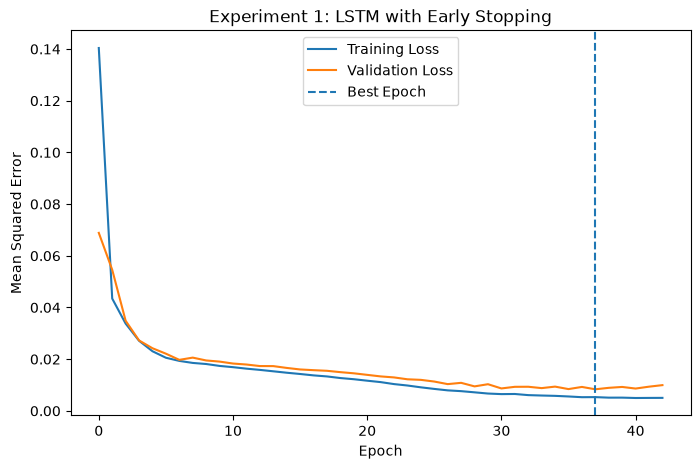

In [76]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_earlystop.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_earlystop.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Experiment 1: LSTM with Early Stopping")

plt.legend()
plt.show()

## 59. Experiment 1 Result

The early-stopping model trained for 53 epochs and achieved its best validation loss at epoch 48.

The best validation loss was:

- Best validation loss: 0.0074853

Early stopping was configured to monitor validation loss with a patience of 5 epochs and to restore the model weights from the best validation epoch.

The result indicates that early stopping can prevent unnecessary training after validation performance stops improving.

## 60. Experiment 2: Dropout

The second tuning experiment evaluates dropout as an additional overfitting-control method.

The LSTM architecture and training settings remain the same as Experiment 1, while a dropout layer with a rate of 0.20 is added after the LSTM layer.

This allows the effect of dropout to be evaluated independently.

## 61


In [77]:
dropout_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(32),
    Dropout(0.20),
    Dense(2)
])

dropout_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [78]:
dropout_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 32)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,546 (17.76 KB)

 Trainable params: 4,546 (17.76 KB)

 Non-trainable params: 0 (0.00 B)

### 62 Create a Fresh Early-Stopping Callback

In [79]:
early_stop_dropout = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

### 63. Train Experiment 2

In [80]:
history_dropout = dropout_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_dropout],
    verbose=1
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2580 - mae: 0.4416 - val_loss: 0.1330 - val_mae: 0.2762
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1163 - mae: 0.2699 - val_loss: 0.0488 - val_mae: 0.1840
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0460 - mae: 0.1661 - val_loss: 0.0405 - val_mae: 0.1788
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0357 - mae: 0.1515 - val_loss: 0.0354 - val_mae: 0.1637
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0313 - mae: 0.1396 - val_loss: 0.0249 - val_mae: 0.1343
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0291 - mae: 0.1333 - val_loss: 0.0251 - val_mae: 0.1332
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0242 - mae: 0.1256 - val_loss: 0.0235 - val_mae: 0.1240
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0251 - mae: 0.1237 - val_loss: 0.0242 - val_mae: 0.1269
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.02

### 64. Get Experiment 2 Results

In [81]:
dropout_epochs_ran = len(
    history_dropout.history["loss"]
)

dropout_best_val_loss = min(
    history_dropout.history["val_loss"]
)

dropout_best_epoch = (
    np.argmin(
        history_dropout.history["val_loss"]
    ) + 1
)

print("Epochs actually run:", dropout_epochs_ran)
print("Best epoch:", dropout_best_epoch)
print("Best validation loss:", dropout_best_val_loss)

Epochs actually run: 58
Best epoch: 53
Best validation loss: 0.007439423352479935


### 65. Plot Experiment 2

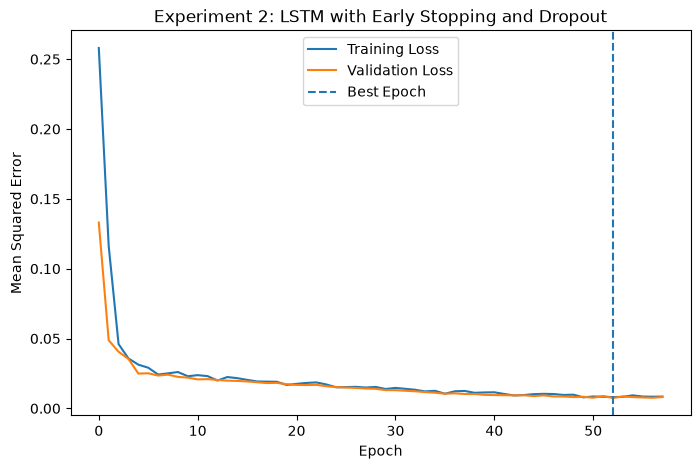

In [82]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_dropout.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_dropout.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    dropout_best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Experiment 2: LSTM with Early Stopping and Dropout")

plt.legend()
plt.show()

## 66. Early-Stopping and Dropout Comparison

The validation performance of the early-stopping model and the dropout model is compared to determine whether adding dropout improves generalization.

In [83]:
print("Experiment 1 - Early Stopping Only")
print("Best validation loss:", best_val_loss)

print("\nExperiment 2 - Early Stopping + Dropout")
print("Best validation loss:", dropout_best_val_loss)

Experiment 1 - Early Stopping Only
Best validation loss: 0.008342640474438667

Experiment 2 - Early Stopping + Dropout
Best validation loss: 0.007439423352479935


## 67. Reproducibility Seed

A fixed random seed is used during model experimentation to improve reproducibility and ensure that model configurations are compared under consistent random initialization conditions.

The same seed is reset before each experimental model is created.

In [84]:
RANDOM_SEED = 42

keras.utils.set_random_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


## 68. Reproducible Experiment 1: Early Stopping

Experiment 1 is repeated using a fixed random seed so that subsequent hyperparameter configurations can be compared under more consistent initialization conditions.

In [85]:
keras.utils.set_random_seed(RANDOM_SEED)

exp1_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(32),
    Dense(2)
])

exp1_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

exp1_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [86]:
exp1_history = exp1_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[exp1_early_stop],
    verbose=0
)

In [87]:
exp1_epochs = len(exp1_history.history["loss"])

exp1_best_epoch = (
    np.argmin(exp1_history.history["val_loss"]) + 1
)

exp1_best_loss = min(
    exp1_history.history["val_loss"]
)

print("Experiment 1")
print("Epochs actually run:", exp1_epochs)
print("Best epoch:", exp1_best_epoch)
print("Best validation loss:", exp1_best_loss)

Experiment 1
Epochs actually run: 43
Best epoch: 38
Best validation loss: 0.008216667920351028


In [88]:
keras.utils.set_random_seed(RANDOM_SEED)

## 69. Reproducible Experiment 2: Dropout

Experiment 2 is repeated using the same fixed random seed as Experiment 1.

The only architectural difference is the addition of a dropout layer with a rate of 0.20.

In [89]:
keras.utils.set_random_seed(RANDOM_SEED)

exp2_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(32),
    Dropout(0.20),
    Dense(2)
])

exp2_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

exp2_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [90]:
exp2_history = exp2_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[exp2_early_stop],
    verbose=0
)

In [91]:
exp2_epochs = len(exp2_history.history["loss"])

exp2_best_epoch = (
    np.argmin(exp2_history.history["val_loss"]) + 1
)

exp2_best_loss = min(
    exp2_history.history["val_loss"]
)

print("Experiment 2")
print("Epochs actually run:", exp2_epochs)
print("Best epoch:", exp2_best_epoch)
print("Best validation loss:", exp2_best_loss)

Experiment 2
Epochs actually run: 60
Best epoch: 55
Best validation loss: 0.006550468038767576


## 70. Reproducible Comparison of Experiments 1 and 2

The early-stopping-only configuration and the dropout configuration are compared using their minimum validation losses after training with the same fixed random seed.

In [92]:
comparison_1_2 = pd.DataFrame({
    "Experiment": [
        "Exp 1 - Early Stopping",
        "Exp 2 - Dropout 0.20"
    ],
    "Best Epoch": [
        exp1_best_epoch,
        exp2_best_epoch
    ],
    "Epochs Run": [
        exp1_epochs,
        exp2_epochs
    ],
    "Best Validation Loss": [
        exp1_best_loss,
        exp2_best_loss
    ]
})

comparison_1_2

,Experiment,Best Epoch,Epochs Run,Best Validation Loss
0,Exp 1 - Early Stopping,38,43,0.008217
1,Exp 2 - Dropout 0.20,55,60,0.006550


## 71. Comparison of Early Stopping and Dropout

Using a fixed random seed, the early-stopping-only model achieved a best validation loss of 0.008217 at epoch 38.

The model with early stopping and a dropout rate of 0.20 achieved a lower best validation loss of 0.006550 at epoch 55.

Because the dropout configuration produced the better validation result under the same random seed, a dropout rate of 0.20 is retained as the current best configuration for subsequent experiments.

## 72. Experiment 3: LSTM Unit Size

The third tuning experiment evaluates the number of LSTM units.

Three configurations are compared:

- 16 LSTM units
- 32 LSTM units
- 64 LSTM units

All other settings are kept constant, including the 0.20 dropout rate, batch size of 16, Adam optimizer, six-hour input sequence, and early stopping with a patience of 5 epochs.

### 73

In [93]:
def train_units_experiment(units):
    
    keras.utils.set_random_seed(RANDOM_SEED)
    
    model = Sequential([
        keras.Input(shape=(6, 2)),
        LSTM(units),
        Dropout(0.20),
        Dense(2)
    ])
    
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
    
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        verbose=0
    )
    
    best_epoch = np.argmin(
        history.history["val_loss"]
    ) + 1
    
    best_loss = min(
        history.history["val_loss"]
    )
    
    epochs_run = len(
        history.history["loss"]
    )
    
    return model, history, best_epoch, best_loss, epochs_run

### 74

In [94]:
model_16, history_16, best_epoch_16, best_loss_16, epochs_16 = train_units_experiment(16)

print("16 LSTM Units")
print("Best epoch:", best_epoch_16)
print("Epochs run:", epochs_16)
print("Best validation loss:", best_loss_16)

16 LSTM Units
Best epoch: 74
Epochs run: 79
Best validation loss: 0.00597139447927475


### 75 run 32-unit experiment

In [95]:
model_32, history_32, best_epoch_32, best_loss_32, epochs_32 = train_units_experiment(32)

print("32 LSTM Units")
print("Best epoch:", best_epoch_32)
print("Epochs run:", epochs_32)
print("Best validation loss:", best_loss_32)

32 LSTM Units
Best epoch: 55
Epochs run: 60
Best validation loss: 0.006550468038767576


### 76 run 64-unit experiment

In [96]:
model_64, history_64, best_epoch_64, best_loss_64, epochs_64 = train_units_experiment(64)

print("64 LSTM Units")
print("Best epoch:", best_epoch_64)
print("Epochs run:", epochs_64)
print("Best validation loss:", best_loss_64)

64 LSTM Units
Best epoch: 38
Epochs run: 43
Best validation loss: 0.0069131385535001755


### 77. compare unit sizes

In [97]:
units_comparison = pd.DataFrame({
    "LSTM Units": [
        16,
        32,
        64
    ],
    "Best Epoch": [
        best_epoch_16,
        best_epoch_32,
        best_epoch_64
    ],
    "Epochs Run": [
        epochs_16,
        epochs_32,
        epochs_64
    ],
    "Best Validation Loss": [
        best_loss_16,
        best_loss_32,
        best_loss_64
    ]
})

units_comparison

,LSTM Units,Best Epoch,Epochs Run,Best Validation Loss
0,16,74,79,0.005971
1,32,55,60,0.006550
2,64,38,43,0.006913


In [98]:
best_units_row = units_comparison.loc[
    units_comparison["Best Validation Loss"].idxmin()
]

print("Best LSTM units:", int(best_units_row["LSTM Units"]))
print("Best validation loss:", best_units_row["Best Validation Loss"])

Best LSTM units: 16
Best validation loss: 0.00597139447927475


## 78. Experiment 3 Result: LSTM Units

Three LSTM unit sizes were evaluated using the same fixed random seed and training configuration.

- 16 units: best validation loss = 0.005971
- 32 units: best validation loss = 0.006550
- 64 units: best validation loss = 0.006913

The 16-unit LSTM achieved the lowest validation loss. Therefore, 16 LSTM units are retained as the current best configuration for subsequent experiments.

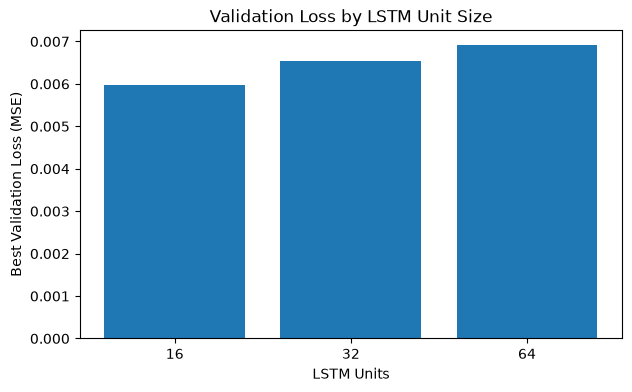

In [99]:
plt.figure(figsize=(7, 4))

plt.bar(
    units_comparison["LSTM Units"].astype(str),
    units_comparison["Best Validation Loss"]
)

plt.xlabel("LSTM Units")
plt.ylabel("Best Validation Loss (MSE)")
plt.title("Validation Loss by LSTM Unit Size")

plt.show()

## 79. Experiment 4: Number of LSTM Layers

The fourth tuning experiment evaluates whether increasing the LSTM depth improves validation performance.

Two configurations are compared:

- One LSTM layer with 16 units
- Two LSTM layers with 16 units each

The sequence length, dropout rate, batch size, optimizer, and early-stopping settings are kept constant.

80. Train the 1-Layer Model

In [100]:
keras.utils.set_random_seed(RANDOM_SEED)

layer1_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(16),
    Dropout(0.20),
    Dense(2)
])

layer1_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

layer1_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

layer1_history = layer1_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[layer1_early_stop],
    verbose=0
)

In [101]:
layer1_best_epoch = (
    np.argmin(layer1_history.history["val_loss"]) + 1
)

layer1_best_loss = min(
    layer1_history.history["val_loss"]
)

layer1_epochs = len(
    layer1_history.history["loss"]
)

print("1 LSTM Layer")
print("Best epoch:", layer1_best_epoch)
print("Epochs run:", layer1_epochs)
print("Best validation loss:", layer1_best_loss)

1 LSTM Layer
Best epoch: 74
Epochs run: 79
Best validation loss: 0.00597139447927475


81. Train the 2-Layer Model

In [102]:
return_sequences=True

In [103]:
keras.utils.set_random_seed(RANDOM_SEED)

layer2_model = Sequential([
    keras.Input(shape=(6, 2)),

    LSTM(
        16,
        return_sequences=True
    ),

    Dropout(0.20),

    LSTM(16),

    Dropout(0.20),

    Dense(2)
])

layer2_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

layer2_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

layer2_history = layer2_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[layer2_early_stop],
    verbose=0
)

In [104]:
layer2_best_epoch = (
    np.argmin(layer2_history.history["val_loss"]) + 1
)

layer2_best_loss = min(
    layer2_history.history["val_loss"]
)

layer2_epochs = len(
    layer2_history.history["loss"]
)

print("2 LSTM Layers")
print("Best epoch:", layer2_best_epoch)
print("Epochs run:", layer2_epochs)
print("Best validation loss:", layer2_best_loss)

2 LSTM Layers
Best epoch: 70
Epochs run: 75
Best validation loss: 0.010909542441368103


82. Compare 1 vs 2 Layers

In [105]:
layers_comparison = pd.DataFrame({
    "LSTM Layers": [
        1,
        2
    ],
    "Units per Layer": [
        "16",
        "16 + 16"
    ],
    "Best Epoch": [
        layer1_best_epoch,
        layer2_best_epoch
    ],
    "Epochs Run": [
        layer1_epochs,
        layer2_epochs
    ],
    "Best Validation Loss": [
        layer1_best_loss,
        layer2_best_loss
    ]
})

layers_comparison

,LSTM Layers,Units per Layer,Best Epoch,Epochs Run,Best Validation Loss
0,1,16,74,79,0.005971
1,2,16 + 16,70,75,0.010910


In [106]:
best_layers_row = layers_comparison.loc[
    layers_comparison["Best Validation Loss"].idxmin()
]

print(
    "Best number of LSTM layers:",
    int(best_layers_row["LSTM Layers"])
)

print(
    "Best validation loss:",
    best_layers_row["Best Validation Loss"]
)

Best number of LSTM layers: 1
Best validation loss: 0.00597139447927475


## 83. Experiment 4 Result: Number of LSTM Layers

The one-layer LSTM achieved a best validation loss of 0.005971, while the two-layer LSTM achieved a higher best validation loss of 0.010910.

Because the single-layer architecture produced substantially better validation performance, one LSTM layer is retained as the current best architecture.

The result also supports the use of a simpler model for the available dataset, reducing computational complexity while maintaining better validation performance.

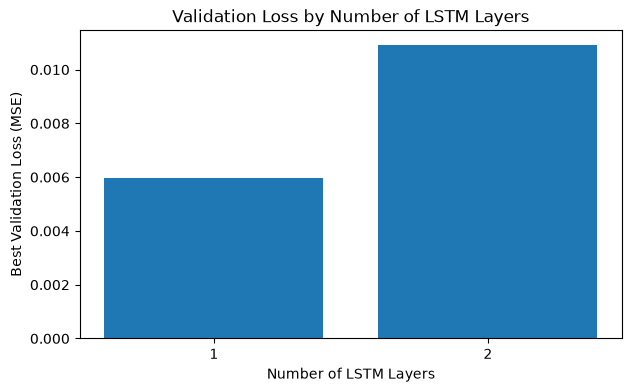

In [107]:
plt.figure(figsize=(7, 4))

plt.bar(
    layers_comparison["LSTM Layers"].astype(str),
    layers_comparison["Best Validation Loss"]
)

plt.xlabel("Number of LSTM Layers")
plt.ylabel("Best Validation Loss (MSE)")
plt.title("Validation Loss by Number of LSTM Layers")

plt.show()

## 84. Experiment 5: Batch Size

The fifth tuning experiment evaluates the effect of batch size on validation performance.

Three batch sizes are compared:

- 8
- 16
- 32

All other model architecture and training settings are kept constant.

### 85. Create the Batch-Size Experiment Function

In [108]:
def train_batch_experiment(batch_size):

    keras.utils.set_random_seed(RANDOM_SEED)

    model = Sequential([
        keras.Input(shape=(6, 2)),
        LSTM(16),
        Dropout(0.20),
        Dense(2)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )

    best_epoch = np.argmin(
        history.history["val_loss"]
    ) + 1

    best_loss = min(
        history.history["val_loss"]
    )

    epochs_run = len(
        history.history["loss"]
    )

    return model, history, best_epoch, best_loss, epochs_run

### 86. Test Batch Size 8

In [109]:
batch8_model, batch8_history, batch8_best_epoch, batch8_best_loss, batch8_epochs = train_batch_experiment(8)

print("Batch Size 8")
print("Best epoch:", batch8_best_epoch)
print("Epochs run:", batch8_epochs)
print("Best validation loss:", batch8_best_loss)

Batch Size 8
Best epoch: 52
Epochs run: 57
Best validation loss: 0.005591156426817179


### 87. Test Batch Size 16

In [110]:
batch16_model, batch16_history, batch16_best_epoch, batch16_best_loss, batch16_epochs = train_batch_experiment(16)

print("Batch Size 16")
print("Best epoch:", batch16_best_epoch)
print("Epochs run:", batch16_epochs)
print("Best validation loss:", batch16_best_loss)

Batch Size 16
Best epoch: 74
Epochs run: 79
Best validation loss: 0.00597139447927475


### 88. Test Batch Size 32

In [111]:
batch32_model, batch32_history, batch32_best_epoch, batch32_best_loss, batch32_epochs = train_batch_experiment(32)

print("Batch Size 32")
print("Best epoch:", batch32_best_epoch)
print("Epochs run:", batch32_epochs)
print("Best validation loss:", batch32_best_loss)

Batch Size 32
Best epoch: 78
Epochs run: 83
Best validation loss: 0.007477946113795042


### 89. Compare Batch Sizes

In [112]:
batch_comparison = pd.DataFrame({
    "Batch Size": [
        8,
        16,
        32
    ],
    "Best Epoch": [
        batch8_best_epoch,
        batch16_best_epoch,
        batch32_best_epoch
    ],
    "Epochs Run": [
        batch8_epochs,
        batch16_epochs,
        batch32_epochs
    ],
    "Best Validation Loss": [
        batch8_best_loss,
        batch16_best_loss,
        batch32_best_loss
    ]
})

batch_comparison

,Batch Size,Best Epoch,Epochs Run,Best Validation Loss
0,8,52,57,0.005591
1,16,74,79,0.005971
2,32,78,83,0.007478


In [113]:
best_batch_row = batch_comparison.loc[
    batch_comparison["Best Validation Loss"].idxmin()
]

print(
    "Best batch size:",
    int(best_batch_row["Batch Size"])
)

print(
    "Best validation loss:",
    best_batch_row["Best Validation Loss"]
)

Best batch size: 8
Best validation loss: 0.005591156426817179


## 90. Experiment 5 Result: Batch Size

Three batch sizes were evaluated using the current best LSTM architecture.

- Batch size 8: best validation loss = 0.005591
- Batch size 16: best validation loss = 0.005971
- Batch size 32: best validation loss = 0.007478

Batch size 8 achieved the lowest validation loss. Therefore, a batch size of 8 is retained for subsequent tuning experiments.

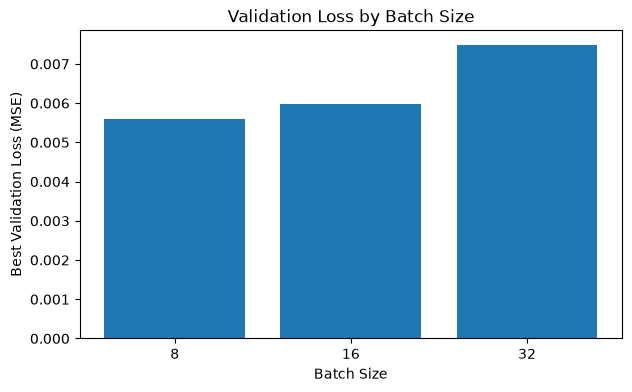

In [114]:
plt.figure(figsize=(7, 4))

plt.bar(
    batch_comparison["Batch Size"].astype(str),
    batch_comparison["Best Validation Loss"]
)

plt.xlabel("Batch Size")
plt.ylabel("Best Validation Loss (MSE)")
plt.title("Validation Loss by Batch Size")

plt.show()

## 91. Experiment 6: Learning Rate

The sixth tuning experiment evaluates the learning rate used by the Adam optimizer.

Three learning rates are compared:

- 0.0005
- 0.001
- 0.005

All other settings are kept constant using the current best model configuration.

In [115]:
from keras.optimizers import Adam

### 93. Create the Learning-Rate Experiment Function

In [116]:
def train_learning_rate_experiment(learning_rate):

    keras.utils.set_random_seed(RANDOM_SEED)

    model = Sequential([
        keras.Input(shape=(6, 2)),
        LSTM(16),
        Dropout(0.20),
        Dense(2)
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=8,
        callbacks=[early_stop],
        verbose=0
    )

    best_epoch = (
        np.argmin(
            history.history["val_loss"]
        ) + 1
    )

    best_loss = min(
        history.history["val_loss"]
    )

    epochs_run = len(
        history.history["loss"]
    )

    return model, history, best_epoch, best_loss, epochs_run

### 94. Test Learning Rate 0.0005

In [117]:
lr_0005_model, lr_0005_history, lr_0005_best_epoch, lr_0005_best_loss, lr_0005_epochs = train_learning_rate_experiment(
    0.0005
)

print("Learning Rate 0.0005")
print("Best epoch:", lr_0005_best_epoch)
print("Epochs run:", lr_0005_epochs)
print("Best validation loss:", lr_0005_best_loss)

Learning Rate 0.0005
Best epoch: 68
Epochs run: 73
Best validation loss: 0.006880284287035465


### 95. Test Learning Rate 0.001

In [118]:
lr_001_model, lr_001_history, lr_001_best_epoch, lr_001_best_loss, lr_001_epochs = train_learning_rate_experiment(
    0.001
)

print("Learning Rate 0.001")
print("Best epoch:", lr_001_best_epoch)
print("Epochs run:", lr_001_epochs)
print("Best validation loss:", lr_001_best_loss)

Learning Rate 0.001
Best epoch: 52
Epochs run: 57
Best validation loss: 0.005591156426817179


### 96. Test Learning Rate 0.005

In [119]:
lr_005_model, lr_005_history, lr_005_best_epoch, lr_005_best_loss, lr_005_epochs = train_learning_rate_experiment(
    0.005
)

print("Learning Rate 0.005")
print("Best epoch:", lr_005_best_epoch)
print("Epochs run:", lr_005_epochs)
print("Best validation loss:", lr_005_best_loss)

Learning Rate 0.005
Best epoch: 20
Epochs run: 25
Best validation loss: 0.004851053468883038


### 97. Compare Learning Rates

In [120]:
learning_rate_comparison = pd.DataFrame({
    "Learning Rate": [
        0.0005,
        0.001,
        0.005
    ],
    "Best Epoch": [
        lr_0005_best_epoch,
        lr_001_best_epoch,
        lr_005_best_epoch
    ],
    "Epochs Run": [
        lr_0005_epochs,
        lr_001_epochs,
        lr_005_epochs
    ],
    "Best Validation Loss": [
        lr_0005_best_loss,
        lr_001_best_loss,
        lr_005_best_loss
    ]
})

learning_rate_comparison

,Learning Rate,Best Epoch,Epochs Run,Best Validation Loss
0,0.0005,68,73,0.006880
1,0.0010,52,57,0.005591
2,0.0050,20,25,0.004851


In [121]:
best_lr_row = learning_rate_comparison.loc[
    learning_rate_comparison["Best Validation Loss"].idxmin()
]

print(
    "Best learning rate:",
    best_lr_row["Learning Rate"]
)

print(
    "Best validation loss:",
    best_lr_row["Best Validation Loss"]
)

Best learning rate: 0.005
Best validation loss: 0.004851053468883038


## 98. Experiment 6 Result: Learning Rate

Three learning rates were evaluated using the current best LSTM configuration.

- Learning rate 0.0005: best validation loss = 0.006880
- Learning rate 0.001: best validation loss = 0.005591
- Learning rate 0.005: best validation loss = 0.004851

The learning rate of 0.005 achieved the lowest validation loss and reached its best validation performance at epoch 20.

Therefore, a learning rate of 0.005 is retained as the current best setting for subsequent experiments.

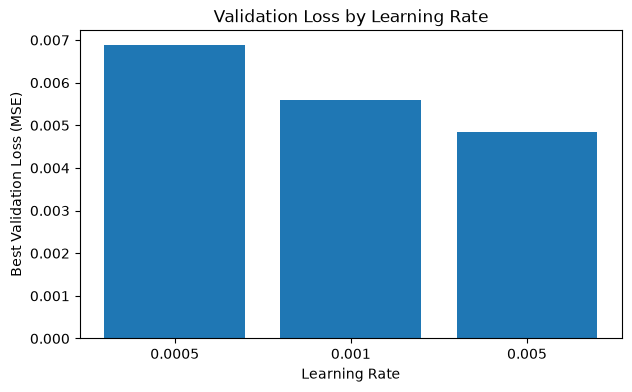

In [122]:
plt.figure(figsize=(7, 4))

plt.bar(
    learning_rate_comparison["Learning Rate"].astype(str),
    learning_rate_comparison["Best Validation Loss"]
)

plt.xlabel("Learning Rate")
plt.ylabel("Best Validation Loss (MSE)")
plt.title("Validation Loss by Learning Rate")

plt.show()

## 99. Experiment 7: Sequence Length

The seventh tuning experiment evaluates the amount of historical information provided to the LSTM.

Two sequence lengths are compared:

- 6 previous hourly observations
- 12 previous hourly observations

Both configurations forecast water pH and water temperature one hour ahead.

All model hyperparameters are kept constant using the current best configuration.

### 100. Generate 12-Hour Sequences

In [123]:
X_train_12, y_train_12 = create_segment_sequences(
    train_df,
    train_scaled,
    12
)

X_val_12, y_val_12 = create_segment_sequences(
    val_df,
    val_scaled,
    12
)

X_test_12, y_test_12 = create_segment_sequences(
    test_df,
    test_scaled,
    12
)

In [124]:
print("6-hour sequences:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\n12-hour sequences:")
print("Train:", X_train_12.shape, y_train_12.shape)
print("Validation:", X_val_12.shape, y_val_12.shape)
print("Test:", X_test_12.shape, y_test_12.shape)

6-hour sequences:
Train: (236, 6, 2) (236, 2)
Validation: (35, 6, 2) (35, 2)
Test: (29, 6, 2) (29, 2)

12-hour sequences:
Train: (169, 12, 2) (169, 2)
Validation: (7, 12, 2) (7, 2)
Test: (6, 12, 2) (6, 2)


## 101. Final Sequence-Length Decision

The six-hour and twelve-hour input windows were assessed for sequence availability.

The six-hour configuration produced:

- 236 training sequences
- 35 validation sequences
- 29 test sequences

The twelve-hour configuration produced:

- 169 training sequences
- 7 validation sequences
- 6 test sequences

Although the twelve-hour window provides a longer historical context, it substantially reduces the number of validation and test sequences because of gaps in the source time series.

Because only seven validation sequences and six test sequences remained under the twelve-hour configuration, the twelve-hour window was considered insufficient for reliable model selection and evaluation.

Therefore, the six-hour sequence length is retained as the final input window for the source LSTM.

## 102. Final Source LSTM Configuration

Based on the validation-based tuning experiments, the final source LSTM configuration is:

- Input variables: water pH and water temperature
- Sequence length: 6 hourly observations
- Forecast horizon: 1 hour ahead
- LSTM layers: 1
- LSTM units: 16
- Dropout rate: 0.20
- Optimizer: Adam
- Learning rate: 0.005
- Batch size: 8
- Maximum epochs: 100
- Early-stopping patience: 5 epochs
- Early-stopping monitor: validation loss
- Restore best weights: enabled
- Loss function: Mean Squared Error
- Random seed: 42

The final model configuration was selected using validation performance. The held-out test set was not used to select the hyperparameters.

### 103. Build the Final Source Model

In [125]:
keras.utils.set_random_seed(RANDOM_SEED)

final_source_model = Sequential([
    keras.Input(shape=(6, 2)),
    LSTM(16),
    Dropout(0.20),
    Dense(2)
])

final_source_model.compile(
    optimizer=Adam(
        learning_rate=0.005
    ),
    loss="mse",
    metrics=["mae"]
)

final_source_model.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_17 (LSTM)                  │ (None, 16)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,250 (4.88 KB)

 Trainable params: 1,250 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

### 104. Create Final Early Stopping

In [126]:
final_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

## 105. Final Source Model Training

The final source LSTM is trained using the selected hyperparameters.

Early stopping monitors validation loss and restores the weights from the best validation epoch.

In [127]:
final_history = final_source_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=8,
    callbacks=[final_early_stop],
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0337 - mae: 0.1436 - val_loss: 0.0163 - val_mae: 0.1008
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0215 - mae: 0.1104 - val_loss: 0.0168 - val_mae: 0.1098
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0190 - mae: 0.1048 - val_loss: 0.0120 - val_mae: 0.0916
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0141 - mae: 0.0916 - val_loss: 0.0107 - val_mae: 0.0749
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0123 - mae: 0.0849 - val_loss: 0.0095 - val_mae: 0.0779
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0115 - mae: 0.0805 - val_loss: 0.0087 - val_mae: 0.0693
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0119 - mae: 0.0821 - val_loss: 0.0093 - val_mae: 0.0727
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0094 - mae: 0.0736 - val_loss: 0.0076 - val_mae: 0.0703
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.009

### 106. Get Final Training Information

In [128]:
final_epochs_run = len(
    final_history.history["loss"]
)

final_best_epoch = (
    np.argmin(
        final_history.history["val_loss"]
    ) + 1
)

final_best_val_loss = min(
    final_history.history["val_loss"]
)

print("Final source model")
print("Epochs actually run:", final_epochs_run)
print("Best epoch:", final_best_epoch)
print("Best validation loss:", final_best_val_loss)

Final source model
Epochs actually run: 25
Best epoch: 20
Best validation loss: 0.004851053468883038


## 107. Final Source Model Training Curve

Training and validation loss are plotted for the final source model to inspect convergence and generalization behavior.

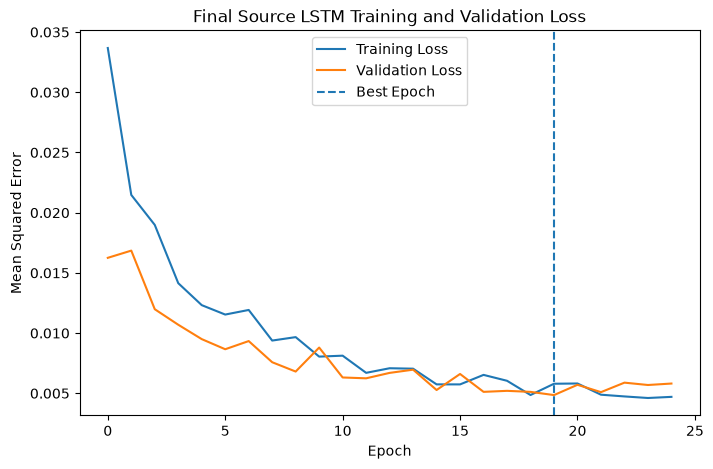

In [129]:
plt.figure(figsize=(8, 5))

plt.plot(
    final_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    final_history.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    final_best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Final Source LSTM Training and Validation Loss")

plt.legend()
plt.show()

In [144]:
# Generate predictions on the source validation set.
source_val_pred_scaled = final_source_model.predict(
    X_val,
    verbose=0
)

# Convert the validation predictions and actual values
# back to the original pH and temperature units.
source_val_pred_original = scaler.inverse_transform(
    source_val_pred_scaled
)

source_val_actual_original = scaler.inverse_transform(
    y_val
)

# Separate pH and temperature.
source_val_actual_ph = source_val_actual_original[:, 0]
source_val_pred_ph = source_val_pred_original[:, 0]

source_val_actual_temp = source_val_actual_original[:, 1]
source_val_pred_temp = source_val_pred_original[:, 1]

# Calculate pH validation metrics.
source_val_ph_mae = mean_absolute_error(
    source_val_actual_ph,
    source_val_pred_ph
)

source_val_ph_rmse = np.sqrt(
    mean_squared_error(
        source_val_actual_ph,
        source_val_pred_ph
    )
)

source_val_ph_r2 = r2_score(
    source_val_actual_ph,
    source_val_pred_ph
)

# Calculate temperature validation metrics.
source_val_temp_mae = mean_absolute_error(
    source_val_actual_temp,
    source_val_pred_temp
)

source_val_temp_rmse = np.sqrt(
    mean_squared_error(
        source_val_actual_temp,
        source_val_pred_temp
    )
)

source_val_temp_r2 = r2_score(
    source_val_actual_temp,
    source_val_pred_temp
)

print("SOURCE MODEL VALIDATION METRICS")
print()

print("pH")
print("MAE:", source_val_ph_mae)
print("RMSE:", source_val_ph_rmse)
print("R²:", source_val_ph_r2)

print()

print("Temperature")
print("MAE:", source_val_temp_mae)
print("RMSE:", source_val_temp_rmse)
print("R²:", source_val_temp_r2)

SOURCE MODEL VALIDATION METRICS

pH
MAE: 0.10228232845736296
RMSE: 0.1449907317104649
R²: 0.9117660387282136

Temperature
MAE: 0.09609688734740313
RMSE: 0.1344310113946005
R²: 0.8553928209768284


## 108. Final Source Model Test Predictions

The final tuned source LSTM is evaluated on the held-out test sequences.

The test set was not used during hyperparameter selection.

In [130]:
final_pred_scaled = final_source_model.predict(
    X_test,
    verbose=0
)

print("Prediction shape:", final_pred_scaled.shape)
print("Actual shape:", y_test.shape)

Prediction shape: (29, 2)
Actual shape: (29, 2)


### 109. Inverse Transform Final Predictions

In [131]:
final_pred_original = scaler.inverse_transform(
    final_pred_scaled
)

final_test_original = scaler.inverse_transform(
    y_test
)

In [132]:
final_actual_ph = final_test_original[:, 0]
final_actual_temp = final_test_original[:, 1]

final_pred_ph = final_pred_original[:, 0]
final_pred_temp = final_pred_original[:, 1]

### 110. Calculate Final Source Metrics

In [133]:
final_ph_mae = mean_absolute_error(
    final_actual_ph,
    final_pred_ph
)

final_ph_rmse = np.sqrt(
    mean_squared_error(
        final_actual_ph,
        final_pred_ph
    )
)

final_ph_r2 = r2_score(
    final_actual_ph,
    final_pred_ph
)


final_temp_mae = mean_absolute_error(
    final_actual_temp,
    final_pred_temp
)

final_temp_rmse = np.sqrt(
    mean_squared_error(
        final_actual_temp,
        final_pred_temp
    )
)

final_temp_r2 = r2_score(
    final_actual_temp,
    final_pred_temp
)


print("FINAL SOURCE MODEL")

print("\nWATER pH")
print("MAE :", final_ph_mae)
print("RMSE:", final_ph_rmse)
print("R²  :", final_ph_r2)

print("\nWATER TEMPERATURE")
print("MAE :", final_temp_mae)
print("RMSE:", final_temp_rmse)
print("R²  :", final_temp_r2)

FINAL SOURCE MODEL

WATER pH
MAE : 0.1287143015911107
RMSE: 0.17699319142403663
R²  : 0.765836594479587

WATER TEMPERATURE
MAE : 0.09373645313837078
RMSE: 0.11498558755000254
R²  : 0.907427725546715


## 111. Final Source Model Results

The final tuned source LSTM completed training after 25 epochs, with its best validation performance occurring at epoch 20.

The best validation loss was 0.004851.

The final model was evaluated on the held-out source test set containing 29 segment-safe test sequences.

The final source-model performance was:

| Variable | MAE | RMSE | R² |
|---|---:|---:|---:|
| Water pH | 0.1287 | 0.1770 | 0.7658 |
| Water Temperature | 0.0937 | 0.1150 | 0.9074 |

The tuned model improved upon the initial baseline for both forecasting targets. Water temperature achieved the stronger predictive performance, while the pH model also showed substantial improvement over the baseline configuration.

Because the source test partition contains a limited number of valid sequences after accounting for temporal gaps, the reported metrics represent performance on the available held-out source test data.

In [134]:
final_source_metrics = pd.DataFrame({
    "Variable": [
        "Water pH",
        "Water Temperature"
    ],
    "MAE": [
        final_ph_mae,
        final_temp_mae
    ],
    "RMSE": [
        final_ph_rmse,
        final_temp_rmse
    ],
    "R2": [
        final_ph_r2,
        final_temp_r2
    ]
})

final_source_metrics

,Variable,MAE,RMSE,R2
0,Water pH,0.128714,0.176993,0.765837
1,Water Temperature,0.093736,0.114986,0.907428


In [135]:
final_source_metrics.to_csv(
    "../results/source_final_metrics.csv",
    index=False
)

print("Final source metrics saved.")

Final source metrics saved.


## 114. Save the Final Source Model

The final tuned source LSTM is saved for later use as the pretrained source model in the transfer-learning stage.

Its learned LSTM parameters will later be transferred to the Philippine target-domain model.

In [136]:
final_source_model.save(
    "../models/source_final.keras"
)

print("Final source model saved.")

Final source model saved.


In [137]:
import joblib

In [138]:
joblib.dump(
    scaler,
    "../models/source_scaler.pkl"
)

print("Source scaler saved.")

Source scaler saved.


## 116. Final Actual versus Predicted Water pH

The final tuned source model's one-hour-ahead pH predictions are compared with the observed test values.

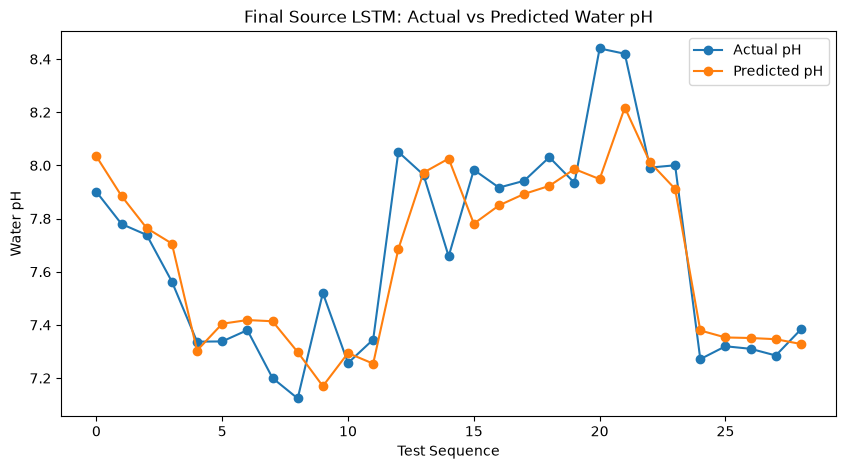

In [139]:
plt.figure(figsize=(10, 5))

plt.plot(
    final_actual_ph,
    marker="o",
    label="Actual pH"
)

plt.plot(
    final_pred_ph,
    marker="o",
    label="Predicted pH"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water pH")
plt.title("Final Source LSTM: Actual vs Predicted Water pH")

plt.legend()
plt.show()

## 117. Final Actual versus Predicted Water Temperature

The final tuned source model's one-hour-ahead water-temperature predictions are compared with the observed test values.

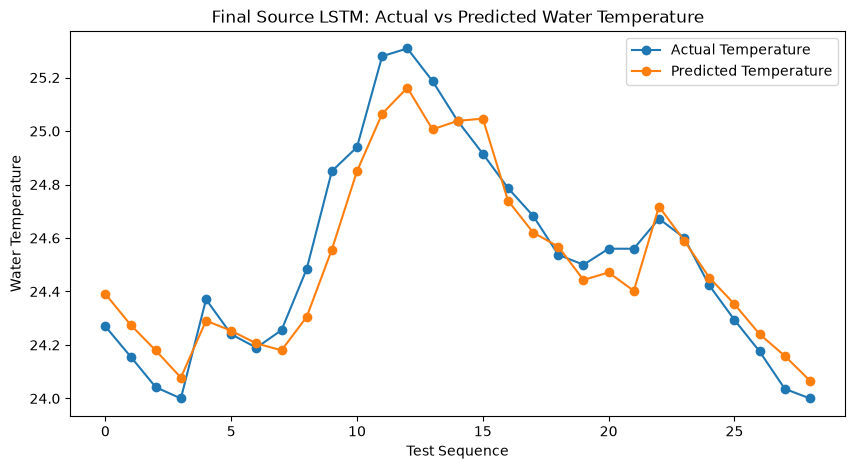

In [140]:
plt.figure(figsize=(10, 5))

plt.plot(
    final_actual_temp,
    marker="o",
    label="Actual Temperature"
)

plt.plot(
    final_pred_temp,
    marker="o",
    label="Predicted Temperature"
)

plt.xlabel("Test Sequence")
plt.ylabel("Water Temperature")
plt.title(
    "Final Source LSTM: Actual vs Predicted Water Temperature"
)

plt.legend()
plt.show()

In [141]:
tuning_summary = pd.DataFrame({
    "Parameter": [
        "Sequence Length",
        "Forecast Horizon",
        "LSTM Layers",
        "LSTM Units",
        "Dropout Rate",
        "Batch Size",
        "Learning Rate",
        "Optimizer",
        "Maximum Epochs",
        "Early Stopping Patience",
        "Early Stopping Monitor",
        "Random Seed"
    ],
    "Selected Value": [
        "6 hours",
        "1 hour ahead",
        1,
        16,
        0.20,
        8,
        0.005,
        "Adam",
        100,
        5,
        "val_loss",
        42
    ]
})

tuning_summary

,Parameter,Selected Value
0,Sequence Length,6 hours
1,Forecast Horizon,1 hour ahead
2,LSTM Layers,1
3,LSTM Units,16
4,Dropout Rate,0.2
5,Batch Size,8
6,Learning Rate,0.005
7,Optimizer,Adam
8,Maximum Epochs,100
9,Early Stopping Patience,5


In [142]:
tuning_summary.to_csv(
    "../results/source_tuning_summary.csv",
    index=False
)

print("Tuning summary saved.")

Tuning summary saved.


In [143]:
units_comparison.to_csv(
    "../results/source_units_experiment.csv",
    index=False
)

layers_comparison.to_csv(
    "../results/source_layers_experiment.csv",
    index=False
)

batch_comparison.to_csv(
    "../results/source_batch_experiment.csv",
    index=False
)

learning_rate_comparison.to_csv(
    "../results/source_learning_rate_experiment.csv",
    index=False
)

comparison_1_2.to_csv(
    "../results/source_dropout_experiment.csv",
    index=False
)

print("Experiment comparison tables saved.")

Experiment comparison tables saved.


## 120. Source LSTM Completion Summary

The source-domain LSTM preprocessing, training, tuning, and evaluation pipeline has been completed.

The final model uses water pH and water temperature as its two input and output variables. Six previous hourly observations are used to forecast both variables one hour ahead.

The final source LSTM configuration consists of one LSTM layer with 16 units, followed by a dropout layer with a rate of 0.20 and a two-unit output layer. The model uses the Adam optimizer with a learning rate of 0.005 and a batch size of 8.

Early stopping monitors validation loss with a patience of five epochs and restores the best model weights.

The final source model achieved:

- Water pH: MAE = 0.1287, RMSE = 0.1770, R² = 0.7658
- Water temperature: MAE = 0.0937, RMSE = 0.1150, R² = 0.9074

The trained source model is saved for subsequent transfer learning using the Philippine target-domain dataset.